Try this with the `ngs-flight-planning/.venv` environment

In [6]:
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr
import datetime
import shapely
import pvlib
import dask
import geoviews as gv
import holoviews as hv
from holoviews import opts as hvopts
from thalassa import api
import thalassa
import matplotlib.pyplot as plt
#
import inputs 
import processing  
import mesh_handling
from timer import SimpleTimer

### Specify configurable details

In [7]:
lines_txt = 'data/AL2401.wpt'
init_datetime = datetime.datetime(2024,12,15,0,0)
datums = ['mllw', 'mhw']

# Image location calculations

Comparing my algorithm for calculating image points against the sample provided by NGS.

In [8]:
# Sample flight paths.
flightpath_filename = 'data/AL2401L-wpt.shp'
imagepoints_filename = 'data/AL2401c-wpt.shp'
flight_paths = gpd.read_file(flightpath_filename)
flight_image_points = gpd.read_file(imagepoints_filename)

In [9]:
# Calculate flight paths.
df_lines = inputs.load_lines_gdf(lines_txt)
df_points = processing.point_table_from_lines(df_lines)

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
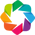

In [10]:
# Set some defaults for the visualization of the graphs
hv.extension("bokeh")
hvopts.defaults(
    hvopts.Image(
        width=800,
        height=600,
        show_title=True,
        tools=["hover"],
        active_tools=["pan", "box_zoom"],
    ),
)

# Plot the points and lines.
flight_path_plot = gv.Path(flight_paths)
flight_image_plot = gv.Points(flight_image_points).opts(color='r', marker='o', size=2)
calc_image_plot = gv.Points(df_points).opts(color='k', marker='x', size=6)
calc_line_plot = gv.Path(df_lines).opts(color='k')

# Get map background.
tiles =  api.get_tiles()

In [11]:
#map_layout
tiles * flight_path_plot * flight_image_plot * calc_image_plot * calc_line_plot

:Overlay
   .WMTS.I    :WMTS   [Longitude,Latitude]
   .Path.I    :Path   [Longitude,Latitude]   (Project,FlightLine,Emulsion,Scale,SensorType,GroundElev,Feet,Miles,Azimuth,Photos,Canceled)
   .Points.I  :Points   [Longitude,Latitude]   (Project,FlightLine,Emulsion,Scale,SensorType,GroundElev,CenterLon,CenterLat,Canceled)
   .Points.II :Points   [Longitude,Latitude]   (LINE,SCALE,EMULSION,GRND_EL,LAT,LON,POINT_NUM)
   .Path.II   :Path   [Longitude,Latitude]   (RECORD,LINE,FEET,SCALE,MILES,FAZI,BAZI,SWP,LAT1,LON1,EWP,LAT2,LON2,EMULSION,LAP,PHOTOS,GRND_EL,MAGDEC,LAT3,LON3,FocalLength(M),FormatX(FT),FormatY(FT))

# Nearest node selections

In [201]:
# Load and subset forecast and datum data.
bbox = mesh_handling.get_box(df_lines)
ds_mesh = mesh_handling.load_forecast_ds(init_datetime, bbox, convert_to_local_msl=True)
ds_mesh = mesh_handling.ds_add_datum(ds_mesh, 'mllw')
ds_mesh = mesh_handling.ds_add_datum(ds_mesh, 'mlw')
ds_mesh = mesh_handling.ds_add_datum(ds_mesh, 'mhw')

Opening data file...
6.465226 s

Assigning grid topology...
6.9666 s

Subsetting...
11.107412 s

Loading dataset...
563.470257 s

Opening LMSL dataset...
2.147386 s

Assigning grid topology...
14.349631 s

Subsetting LMSL data...
7.951496 s

Loading LMSL data...
2.569477 s

Subtracting LMSL...
0.048529 s

Renaming x and y coordinates to match thalassa.


In [202]:
# Select nearest valid nodes
ds_drop = ds_mesh.dropna('node', how='any', subset=['mllw_minus_lmsl', 'zeta'])
ds_drop_zeta = ds_mesh.dropna('node', how='any', subset=['zeta'])
inds, dists = mesh_handling.get_nearest_inds_dists(
    ds_drop,
    df_points,
    n_nearest=1,
    ds_x_var='lon', 
    ds_y_var='lat',
    df_x_var='LON',
    df_y_var='LAT'
)
ds_points_model_timeseries = ds_drop.sel(node=inds).isel(k=0)

In [203]:
# Plot the nearest model node for each image location.
node_points = [shapely.Point(cd[0], cd[1]) 
               for cd in zip(ds_points_model_timeseries.lon.data, 
                             ds_points_model_timeseries.lat.data)]
nearest_node_plot = gv.Points(node_points).opts(color='r', marker='o', size=2)

In [204]:
# Draw lines between each nominal image location and the model node location.
node_lines = [shapely.LineString([p[0], p[1]]) for p in zip(node_points, df_points.geometry)]
node_lines_plot = gv.Path(node_lines)

In [205]:
tiles * calc_image_plot * calc_line_plot * nearest_node_plot * node_lines_plot

:Overlay
   .WMTS.I    :WMTS   [Longitude,Latitude]
   .Points.I  :Points   [Longitude,Latitude]   (LINE,SCALE,EMULSION,GRND_EL,LAT,LON,POINT_NUM)
   .Path.I    :Path   [Longitude,Latitude]   (RECORD,LINE,FEET,SCALE,MILES,FAZI,BAZI,SWP,LAT1,LON1,EWP,LAT2,LON2,EMULSION,LAP,PHOTOS,GRND_EL,MAGDEC,LAT3,LON3,FocalLength(M),FormatX(FT),FormatY(FT))
   .Points.II :Points   [Longitude,Latitude]
   .Path.II   :Path   [Longitude,Latitude]

# Timeseries checks

In [206]:
# Run through the rest of the calculations.

# Calculating tidal range and tolerance.
# Range = MHW - MLW.
# Tolerance based on 2014 NGS/RSD memo.
ds_points_model_timeseries = mesh_handling.ds_add_tidal_range(
    ds_points_model_timeseries
)
ds_points_model_timeseries = mesh_handling.tidal_tol_from_range(
    ds_points_model_timeseries
)

# Interpolating along time axis.
ds_interp = processing.interp_time(ds_points_model_timeseries)

# Converting to pandas data frame.
# Renames the model node lat and lon columns, both for clarity
# and to avoid conflicts when joining with the image location
# lat and lon.
df_interp = ds_interp[[v for v in ds_interp.data_vars if 'station' in ds_interp[v].dims]]\
            .to_dataframe(dim_order=['station', 'time'])\
            .rename(columns={'lat':'node_lat', 'lon':'node_lon'})

# Calculating solar elevation angles.
df_interp = processing.calc_sun_alt(df_interp)

# Calculating times when water level in range.
df_interp = processing.calc_in_range(df_interp, datums)

# Calculating windows by point.
df_point_windows = processing.point_windows_from_bool(df_interp, datums)

# Add line column and reorder.
df_point_windows = df_point_windows.join(df_points.LINE, on='station')\
                                   .rename(columns={'LINE':'line'})
df_point_windows = df_point_windows[['station', 'node_lat', 'node_lon', 
                                     'line', 'datum',
                                     'start_time', 'end_time']]

# Calculating windows by line.
# This is actually done by going back to the boolean time series,
# rather than calculating line windows from point windows.
df_line_windows = processing.line_windows_from_bool(df_interp, df_points, datums)

## Check a single point

In [209]:
# Choose the point
# This corresponds to the index in df_points
i = 500

      station datum          start_time            end_time
3156      500  mllw 2024-12-14 19:00:00 2024-12-14 20:19:00
3157      500  mllw 2024-12-15 18:06:00 2024-12-15 20:19:00
3158      500  mllw 2024-12-16 15:14:00 2024-12-16 15:43:00
3159      500  mllw 2024-12-16 18:21:00 2024-12-16 20:20:00
3160      500  mllw 2024-12-17 15:15:00 2024-12-17 15:58:00
3161      500  mllw 2024-12-17 19:31:00 2024-12-17 20:20:00
3162      500  mllw 2024-12-18 15:16:00 2024-12-18 17:58:00
3163      500  mllw 2024-12-18 18:02:00 2024-12-18 20:20:00
3164      500  mllw 2024-12-19 15:16:00 2024-12-19 17:32:00
3165      500  mllw 2024-12-19 20:11:00 2024-12-19 20:21:00
3166      500  mllw 2024-12-20 15:17:00 2024-12-20 20:21:00
3167      500  mllw 2024-12-21 15:17:00 2024-12-21 20:22:00


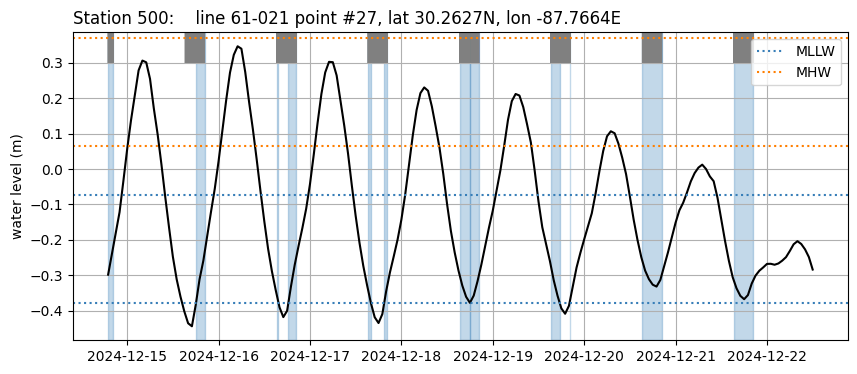

In [208]:
# Plot time series and windows.
cols = ['#377eb8', '#ff7f00', '#4daf4a', '#f781bf']
fig, ax = plt.subplots(figsize=(10,4))
ax.grid()

# Plot water level.
plt.plot(ds_points_model_timeseries.time,
         ds_points_model_timeseries.zeta.isel(station=i), 
         c='k')
ylims = ax.get_ylim()

for idat, dat in enumerate(datums):
    # Plot datums.
    ax.axhline(
        ds_points_model_timeseries[dat + '_minus_lmsl'].isel(station=i) + 
        ds_points_model_timeseries['tolerance'].isel(station=i),
        c=cols[idat], linestyle=':',
        label=dat.upper()
    )
    ax.axhline(
        ds_points_model_timeseries[dat + '_minus_lmsl'].isel(station=i) - 
        ds_points_model_timeseries['tolerance'].isel(station=i),
        c=cols[idat], linestyle=':'
    )

    # Plot time windows.
    df_point_plot = df_point_windows.loc[(df_point_windows.station == i) & (df_point_windows.datum == dat)]
    if not df_point_plot.index.empty:
        for iwindow in df_point_plot.index:
            # Print out interpolated data at this station and time. 
            #print(df_interp.loc[i, df_point_plot.loc[iwindow, 'start_time']])
            #print(df_interp.loc[i, df_point_plot.loc[iwindow, 'end_time']])
            # Shade out areas with solar elevation > 25 degrees.
            df_solel = df_interp.reset_index()
            for t in df_solel.loc[(df_solel.station == i) & (df_solel.solar_elevation >= 25.0), 'time']:
                ax.axvline(t, ymin=0.9, ymax=1.0, c='gray', linewidth=0.1, alpha=0.1)
            # Plot time windows.   
            #ax.axvline(df_point_plot.loc[iwindow, 'start_time'], c=cols[idat])
            #ax.axvline(df_point_plot.loc[iwindow, 'end_time'], c=cols[idat])
            ax.fill_betweenx(
                ylims,
                df_point_plot.loc[iwindow, 'start_time'],
                df_point_plot.loc[iwindow, 'end_time'],
                color=cols[idat], alpha=0.3
            )
    else:
        pass
ax.set_ylim(ylims)
ax.set_title(f'Station {i}:    line {df_points.loc[i, 'LINE']} point #{df_points.loc[i, 'POINT_NUM']},' + 
             f' lat {df_points.loc[i, 'LAT']:.4f}N, lon {df_points.loc[i, 'LON']:.4f}E', 
             loc='left')
ax.legend(loc='upper right')
ax.set_ylabel('water level (m)')

# Also print out windows.
print(df_point_windows.loc[df_point_windows.station == i, ['station', 'datum', 'start_time', 'end_time']])

The plot above shows the water level at the selected station (black) and the chosen datums plus/minus tolerance (horizontal dashed lines). The gray shaded blocks at the top represent times when the solar elevation is greater than 25 degrees. The full height shaded blocks represent the time windows calculated by the algorithm, with color referring to the datum with the same colors as for the horizontal dashed lines. If the algorithm is functioning as intended, the time window blocks should have both water level within tolerance, and solar elevation greater than 25 degrees.

## Check a line

In [210]:
# Choose the line
# This corresponds the the LINE value in df_lines.
line = '61-020'

      line datum          start_time            end_time
88  61-020  mllw 2024-12-14 19:00:00 2024-12-14 20:18:00
89  61-020  mllw 2024-12-15 18:30:00 2024-12-15 20:18:00
90  61-020  mllw 2024-12-16 15:17:00 2024-12-16 17:41:00
91  61-020  mllw 2024-12-16 18:14:00 2024-12-16 20:18:00
92  61-020  mllw 2024-12-17 15:18:00 2024-12-17 16:19:00
93  61-020  mllw 2024-12-18 15:18:00 2024-12-18 17:55:00
94  61-020  mllw 2024-12-18 20:05:00 2024-12-18 20:19:00
95  61-020  mllw 2024-12-19 15:19:00 2024-12-19 16:31:00
96  61-020  mllw 2024-12-20 15:19:00 2024-12-20 20:20:00


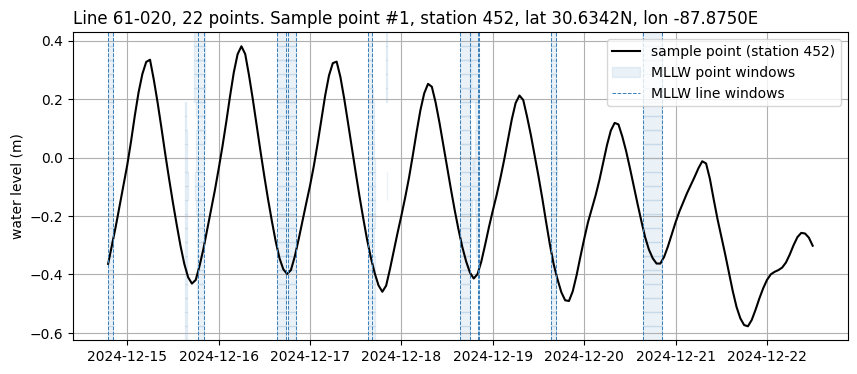

In [211]:
# Plot time series and windows.

# Select the data.
df_line_plot = df_line_windows.loc[df_line_windows.line == line]
df_point_plot = df_point_windows.loc[df_point_windows.line == line]

# Work out mapping from points on this line to interval [0,1].
n_points = df_lines.loc[df_lines.LINE == line, 'PHOTOS'].values[0]
df_ylims = pd.DataFrame(
    data={
        'ymin':np.linspace(0.0, 1.0, n_points, endpoint=False),
        'ymax':np.linspace(1.0/n_points, 1.0, n_points, endpoint=True)
    },
    index=df_points.loc[df_points.LINE == line].index
)
if 'ymin' in df_point_plot.columns:
    df_point_plot = df_point_plot.drop(columns=['ymin', 'ymax'])
df_point_plot = df_point_plot.join(df_ylims, on='station')

# Define function to map from [0,1] to plot limits.
def scale_ylims(val_01, yrange):
    return yrange[0] + (val_01 * (yrange[1] - yrange[0]))
    
# First plot the timeseries from this line's first station, for a base plot.
# Plot time series and windows.
cols = ['#377eb8', '#ff7f00', '#4daf4a', '#f781bf']
fig, ax = plt.subplots(figsize=(10,4))
ax.grid()

# Plot water level.
plt.plot(ds_points_model_timeseries.time,
         ds_points_model_timeseries.zeta.isel(station=df_point_plot.station.iloc[0]),
         c='k',
         label=f'sample point (station {df_point_plot.station.iloc[0]})')
ylims = ax.get_ylim()

for idat, dat in enumerate(datums):
    # Subset points to just this datum.
    df_line_plot_dat = df_line_plot.loc[df_line_plot.datum == dat]
    df_point_plot_dat = df_point_plot.loc[df_point_plot.datum == dat]

    # Plot point-wise time windows.
    if not df_point_plot_dat.index.empty:
        for iwindow in df_point_plot_dat.index: 
            ax.fill_betweenx(
                [scale_ylims(df_point_plot_dat.loc[iwindow, 'ymin'], ylims),
                 scale_ylims(df_point_plot_dat.loc[iwindow, 'ymax'], ylims)],
                df_point_plot_dat.loc[iwindow, 'start_time'],
                df_point_plot_dat.loc[iwindow, 'end_time'],
                color=cols[idat], alpha=0.1,
                label=dat.upper() + ' point windows'
            )
    else:
        pass

    # Plot line-wise time windows.
    if not df_line_plot_dat.index.empty:
        for iwindow in df_line_plot_dat.index: 
            ax.axvline(df_line_plot_dat.loc[iwindow, 'start_time'], 
                       c=cols[idat], linestyle='--', linewidth=0.7,
                       label=dat.upper() + ' line windows')
            ax.axvline(df_line_plot_dat.loc[iwindow, 'end_time'], 
                       c=cols[idat], linestyle='--', linewidth=0.7)
    else:
        pass
        
ax.set_ylim(ylims)

# Plot legend (without duplicate labels).
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper right')

ax.set_ylabel('water level (m)')
ax.set_title(f'Line {line}, {n_points} points. ' + 
             f'Sample point #{df_points.loc[df_point_plot.station.iloc[0], 'POINT_NUM']},' + 
             f' station {df_point_plot.station.iloc[0]},' + 
             f' lat {df_points.loc[df_point_plot.station.iloc[0], 'LAT']:.4f}N, ' + 
             f'lon {df_points.loc[df_point_plot.station.iloc[0], 'LON']:.4f}E', 
             loc='left')

# Also print out windows.
print(df_line_plot)

The plot above shows the line-wise time windows for the selected line as vertical dashed lines, with color corresponding to datum. The black time series is the water level for a single station on this line. It also shows the point-wise time windows for all points on this line (again, color <-> datum), with a discrete vertical location for each point (the actual vertical position has no meaning for these point-wise time windows; they are merely stacked blocks). If the algorithm is functioning correctly, the line-wise time windows should be entirely filled with the relevant color, and there should be no times outside the line-wise windows that have all points shaded. 